<a href="https://colab.research.google.com/github/solon301-vamp/Time-Series-Analysis/blob/main/notebook/24083010100_Analisis_Deret_Waktu_SARIMA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**IMPORT LIBRARY**

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm
from scipy.stats import kruskal, skew
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)

MIN_NILAI = 1_000          # nilai untuk placeholder (Rp1)
BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

#**LOAD DATA & DATA CLEANING**

In [2]:
raw = pd.read_csv("/content/purchase_history.csv")
raw

,po_number,po_date,po_year,po_month_number,po_amount,currency_name
0,145212,1/8/2019,2019,1,"Rp 3,660,000",IDR
1,17,1/8/2019,2019,1,"Rp 63,000,000",IDR
2,28,1/8/2019,2019,1,"Rp 4,500,000",IDR
3,139915,1/9/2019,2019,1,"Rp 70,600,000",IDR
4,15,1/9/2019,2019,1,"Rp 5,100,000",IDR
...,...,...,...,...,...,...
45781,P20086,11/6/2026,2026,11,"Rp 36,396,000",IDR
45782,P20087,11/6/2026,2026,11,"Rp 33,198,000",IDR
45783,P20089,11/6/2026,2026,11,"Rp 6,430,740",IDR
45784,P20099,11/9/2026,2026,11,"Rp 2,996,328",IDR


In [3]:
raw.isnull().sum()

,0
po_number,0
po_date,0
po_year,0
po_month_number,0
po_amount,0
currency_name,0


In [4]:
raw.duplicated().sum()

np.int64(0)

In [5]:
raw.columns = raw.columns.str.strip()
raw["baris_sheet"] = raw.index + 2                    # nomor baris di Google Sheets (baris 1 = header)

df = raw[raw["currency_name"].str.strip() == "IDR"].copy()   # hanya PO rupiah
df["date"] = pd.to_datetime(df["po_date"], format="%m/%d/%Y", errors="coerce")

teks = df["po_amount"].astype(str).str.strip()
df["amount"] = pd.to_numeric(teks.str.replace(r"[^\d.\-]", "", regex=True), errors="coerce")

# Tandai baris bermasalah (urutan = prioritas alasan)
df["masalah"] = np.select(
    [df["date"].isna(),
     teks.eq("-"),
     df["amount"].lt(MIN_NILAI),
     df["amount"].isna()],
    ["tanggal tidak terbaca",
     "nilai strip (Rp 0 / belum diisi)",
     f"nilai < Rp {MIN_NILAI:,} (placeholder)",
     "nilai tidak terbaca"],
    default="")

bermasalah = df.loc[df["masalah"] != "",
                    ["baris_sheet", "po_number", "po_date", "po_amount", "masalah"]]
bermasalah.to_csv("baris_bermasalah.csv", index=False)
data = df[df["masalah"] == ""].copy()          # data bersih untuk analisis

print(f"Baris IDR: {len(df):,} | bermasalah: {len(bermasalah)} | dipakai: {len(data):,}")
print(bermasalah["masalah"].value_counts().to_string())
print(f"Rentang PO: {data['date'].min().date()} s.d. {data['date'].max().date()}")
print("Baris kembar (po_number, tanggal, nilai):",
      data.duplicated(["po_number", "date", "amount"]).sum())
print(data["amount"].describe().map("{:,.0f}".format).to_string())
bermasalah

Baris IDR: 45,786 | bermasalah: 21 | dipakai: 45,765
masalah
nilai strip (Rp 0 / belum diisi)    15
nilai < Rp 1,000 (placeholder)       6
Rentang PO: 2019-01-08 s.d. 2026-11-09
Baris kembar (po_number, tanggal, nilai): 0
count             45,765
mean         159,856,263
std        2,551,607,642
min                6,441
25%            8,036,000
50%           21,929,000
75%           57,816,345
max      281,400,000,000


,baris_sheet,po_number,po_date,po_amount,masalah
562,564,141301,1/31/2019,Rp 1,"nilai < Rp 1,000 (placeholder)"
2596,2598,443,7/9/2019,-,nilai strip (Rp 0 / belum diisi)
3748,3750,780,10/8/2019,-,nilai strip (Rp 0 / belum diisi)
15767,15769,17391,11/26/2021,-,nilai strip (Rp 0 / belum diisi)
17321,17323,19220,3/15/2022,-,nilai strip (Rp 0 / belum diisi)
17464,17466,19392,3/23/2022,-,nilai strip (Rp 0 / belum diisi)
17640,17642,19546,4/4/2022,-,nilai strip (Rp 0 / belum diisi)
17788,17790,19729,4/13/2022,-,nilai strip (Rp 0 / belum diisi)
17895,17897,19739,4/19/2022,-,nilai strip (Rp 0 / belum diisi)
19403,19405,19224,8/25/2022,-,nilai strip (Rp 0 / belum diisi)


In [6]:
data[["baris_sheet", "po_number", "po_date", "date", "amount"]].to_csv(
    "data_bersih.csv", index=False)

print(f"Tersimpan: data_bersih.csv ({len(data):,} baris) | baris_bermasalah.csv ({len(bermasalah)} baris)")

Tersimpan: data_bersih.csv (45,765 baris) | baris_bermasalah.csv (21 baris)


In [7]:
data = pd.read_csv("data_bersih.csv", parse_dates=["date"])
data

,baris_sheet,po_number,po_date,date,amount
0,2,145212,1/8/2019,2019-01-08,3660000.0
1,3,17,1/8/2019,2019-01-08,63000000.0
2,4,28,1/8/2019,2019-01-08,4500000.0
3,5,139915,1/9/2019,2019-01-09,70600000.0
4,6,15,1/9/2019,2019-01-09,5100000.0
...,...,...,...,...,...
45760,45783,P20086,11/6/2026,2026-11-06,36396000.0
45761,45784,P20087,11/6/2026,2026-11-06,33198000.0
45762,45785,P20089,11/6/2026,2026-11-06,6430740.0
45763,45786,P20099,11/9/2026,2026-11-09,2996328.0


#**AGREGASI BULANAN**

In [8]:
bulanan = data.groupby(data["date"].dt.to_period("M"))["amount"].agg(
    total="sum", jumlah_baris="size")
bulanan = bulanan.reindex(
    pd.period_range(bulanan.index.min(), bulanan.index.max(), freq="M"), fill_value=0)

# Buang bulan terakhir hanya jika belum lengkap
akhir_bulan = bulanan.index[-1].to_timestamp(how="end").normalize()
if data["date"].max() < akhir_bulan:
    print(f"Bulan {bulanan.index[-1]} belum lengkap -> dibuang")
    bulanan = bulanan.iloc[:-1]

bulanan.index = bulanan.index.to_timestamp()
nilai_miliar = bulanan["total"] / 1e9              # satuan: miliar Rp

# Simpan agregat bulanan (dipakai langsung untuk modeling)
bulanan.assign(nilai_miliar=nilai_miliar).to_csv("bulanan.csv", index_label="bulan")

print(f"Jumlah bulan: {len(nilai_miliar)} | bulan tanpa PO: {(bulanan['jumlah_baris'] == 0).sum()}")
print("Bulan terbesar (miliar Rp):", nilai_miliar.nlargest(5).round(1).to_dict())

Bulan 2026-11 belum lengkap -> dibuang
Jumlah bulan: 94 | bulan tanpa PO: 0
Bulan terbesar (miliar Rp): {Timestamp('2025-12-01 00:00:00'): 753.3, Timestamp('2026-04-01 00:00:00'): 359.5, Timestamp('2024-03-01 00:00:00'): 321.4, Timestamp('2026-07-01 00:00:00'): 238.3, Timestamp('2025-10-01 00:00:00'): 235.6}


Nilai PO per bulan (miliar Rp):
         Jan    Feb    Mar    Apr   Mei   Jun    Jul    Agu   Sep    Okt    Nov    Des   Total
Tahun                                                                                         
2019    83.6   44.2   37.7   32.1  75.3  26.9   38.9   59.5  50.2   64.5   35.1   41.4   589.3
2020    83.5   24.0  113.8   57.0  41.0  33.8   44.6   47.6  75.3   39.1   63.9   55.7   679.3
2021    51.9   48.3   40.5   24.6  17.0  23.1   17.6   22.4  33.6   24.6   44.6   43.0   391.2
2022    27.1   63.1   75.7   52.7  18.9  47.5   74.8   60.3  72.8   44.3   41.6   90.8   669.5
2023    33.7   34.3   40.6   31.0  39.9  23.7   47.9   60.7  46.7   44.2  114.5   74.1   591.2
2024    65.7  127.6  321.4   31.5  65.3  27.1   45.9   88.2  58.8   89.8   38.5   58.6  1018.4
2025   112.4   59.1  205.0  159.7  61.1  77.4  111.6   92.9  66.4  235.6  103.7  753.3  2038.2
2026    85.8   67.6  121.8  359.5  72.4  92.3  238.3  124.4  76.5   83.0      -      -  1321.6

Jumlah baris PO p

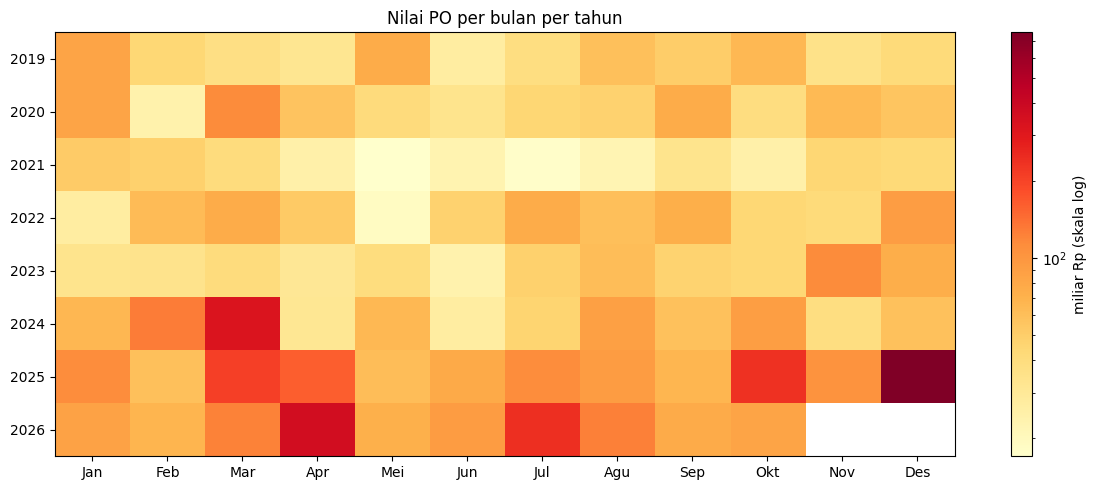

In [9]:
def tabel_bulanan(seri):
    t = seri.groupby([seri.index.year, seri.index.month]).sum().unstack()
    t.columns = [BULAN[c - 1] for c in t.columns]
    t.index.name = "Tahun"
    return t

tabel_nilai = tabel_bulanan(nilai_miliar)
tabel_nilai["Total"] = tabel_nilai.sum(axis=1)
tabel_jumlah = tabel_bulanan(bulanan["jumlah_baris"])
tabel_jumlah["Total"] = tabel_jumlah.sum(axis=1)

print("Nilai PO per bulan (miliar Rp):")
print(tabel_nilai.round(1).to_string(na_rep="-"))
print("\nJumlah baris PO per bulan:")
print(tabel_jumlah.to_string(na_rep="-", float_format="{:.0f}".format))
tabel_nilai.round(2).to_csv("nilai_per_bulan_per_tahun.csv")
tabel_jumlah.to_csv("jumlah_per_bulan_per_tahun.csv")

heat = tabel_nilai.drop(columns="Total").replace(0, np.nan)   # 0 tidak bisa di skala log
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heat, aspect="auto", cmap="YlOrRd", norm=LogNorm())
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(len(heat)), heat.index)
plt.colorbar(im, label="miliar Rp (skala log)")
ax.set_title("Nilai PO per bulan per tahun")
plt.tight_layout()
plt.show()

#**UJI KELAYAKAN (STASIONERITAS DAN MUSIMAN)**

##**STASIONERITAS**

In [10]:
log_nilai = np.log1p(nilai_miliar)
acf_log = acf(log_nilai, nlags=24)

print(f"CV (simpangan baku / rata-rata): {nilai_miliar.std() / nilai_miliar.mean():.2f}")
print(f"ACF log: lag1={acf_log[1]:.2f} | lag12={acf_log[12]:.2f} | lag24={acf_log[24]:.2f}")

def uji_stasioner(x):
    x = x.dropna()
    return pd.Series({"ADF p": adfuller(x)[1], "KPSS p": kpss(x, nlags="auto")[1]})

stasioner = pd.DataFrame({
    "Nilai asli": uji_stasioner(nilai_miliar),
    "Log": uji_stasioner(log_nilai),
    "Log, d=1": uji_stasioner(log_nilai.diff()),
    "Log, D=1 (lag 12)": uji_stasioner(log_nilai.diff(12)),
}).T.round(3)
stasioner["Kesimpulan"] = np.select(
    [(stasioner["ADF p"] < .05) & (stasioner["KPSS p"] >= .05),
     (stasioner["ADF p"] >= .05) & (stasioner["KPSS p"] < .05)],
    ["stasioner", "tidak stasioner"], default="ambigu")
print("\nUji stasioneritas (ADF p < 0.05 dan KPSS p >= 0.05 = stasioner):")
print(stasioner.to_string())

CV (simpangan baku / rata-rata): 1.17
ACF log: lag1=0.41 | lag12=0.26 | lag24=0.10

Uji stasioneritas (ADF p < 0.05 dan KPSS p >= 0.05 = stasioner):
                   ADF p  KPSS p       Kesimpulan
Nilai asli         0.099    0.01  tidak stasioner
Log                0.267    0.01  tidak stasioner
Log, d=1           0.000    0.10        stasioner
Log, D=1 (lag 12)  0.000    0.10        stasioner


##**MUSIMAN**

In [11]:
per_bulan = [log_nilai[log_nilai.index.month == k].values for k in range(1, 13)]
print(f"\nKruskal-Wallis antarbulan: p = {kruskal(*per_bulan)[1]:.3f} (p >= 0.05 = tidak ada musiman nyata)")
indeks = (nilai_miliar.groupby(nilai_miliar.index.month).median() / nilai_miliar.median()).round(2)
indeks.index = BULAN
print("Indeks musiman (median bulan / median total):")
print(indeks.to_string())


Kruskal-Wallis antarbulan: p = 0.616 (p >= 0.05 = tidak ada musiman nyata)
Indeks musiman (median bulan / median total):
Jan    1.29
Feb    0.93
Mar    1.64
Apr    0.73
Mei    0.88
Jun    0.53
Jul    0.81
Agu    1.05
Sep    1.08
Okt    0.94
Nov    0.77
Des    1.01


#**VISUALISASI**

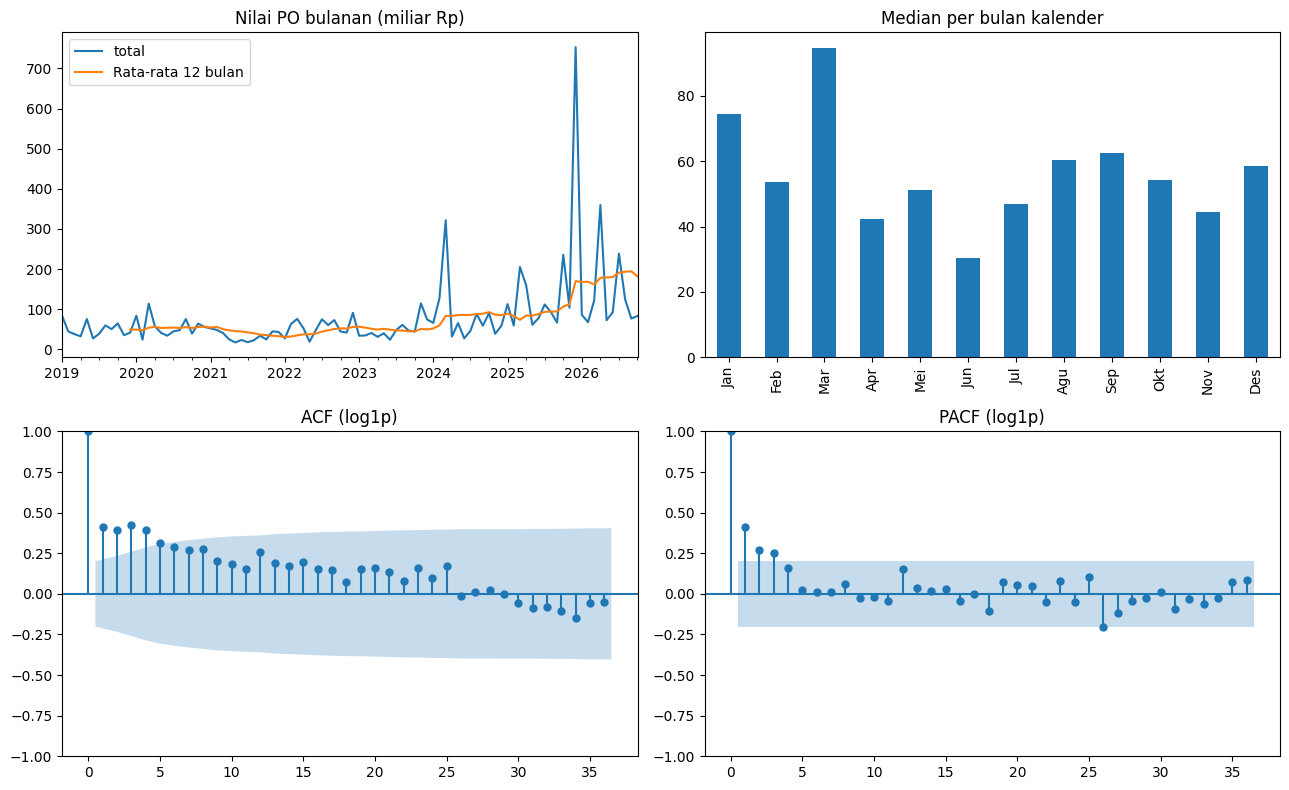

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
nilai_miliar.plot(ax=ax[0, 0], title="Nilai PO bulanan (miliar Rp)")
nilai_miliar.rolling(12).mean().plot(ax=ax[0, 0], label="Rata-rata 12 bulan")
ax[0, 0].legend()
nilai_miliar.groupby(nilai_miliar.index.month).median().set_axis(BULAN).plot.bar(
    ax=ax[0, 1], title="Median per bulan kalender")
plot_acf(log_nilai, lags=36, ax=ax[1, 0], title="ACF (log1p)")
plot_pacf(log_nilai, lags=36, ax=ax[1, 1], title="PACF (log1p)")
plt.tight_layout()
plt.show()

#**PROFIL DATA BULANAN**

Bulan tanpa PO: 0.0%
Top 3 bulan = 19.7% dari total | Top 10% bulan = 34.6%
PO terbesar rata-rata = 20.1% dari total bulannya (median 16.9%) | bulan dengan 1 PO > 50%: 2
Skewness asli = 5.09 | log1p = 1.00
Bulan outlier (miliar Rp): {Timestamp('2024-03-01 00:00:00'): 321.4, Timestamp('2025-12-01 00:00:00'): 753.3, Timestamp('2026-04-01 00:00:00'): 359.5}


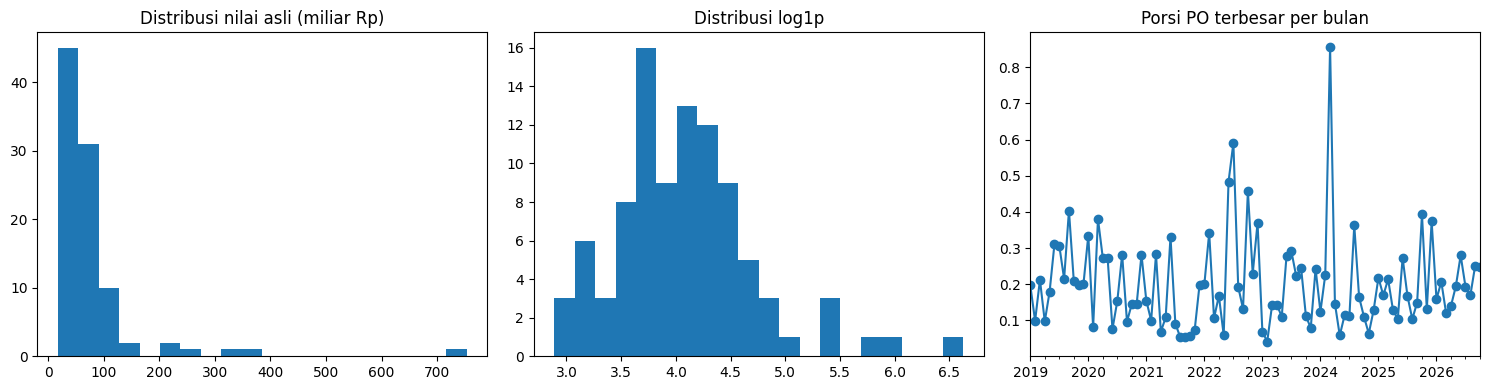

In [14]:
# 1) Bulan kosong
print(f"Bulan tanpa PO: {(bulanan['jumlah_baris'] == 0).mean():.1%}")

# 2) Konsentrasi nilai pada bulan-bulan terbesar
urut = nilai_miliar.sort_values(ascending=False)
print(f"Top 3 bulan = {urut.head(3).sum() / urut.sum():.1%} dari total | "
      f"Top 10% bulan = {urut.head(max(1, len(urut) // 10)).sum() / urut.sum():.1%}")

# 3) Dominasi satu PO terbesar dalam tiap bulan
grup = data.groupby(data["date"].dt.to_period("M").dt.to_timestamp())["amount"]
dominasi = (grup.max() / grup.sum()).reindex(nilai_miliar.index)
print(f"PO terbesar rata-rata = {dominasi.mean():.1%} dari total bulannya "
      f"(median {dominasi.median():.1%}) | bulan dengan 1 PO > 50%: {(dominasi > .5).sum()}")

# 4) Kemiringan & outlier (IQR pada skala log)
print(f"Skewness asli = {skew(nilai_miliar):.2f} | log1p = {skew(log_nilai):.2f}")
q1, q3 = log_nilai.quantile([.25, .75])
batas = (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))
outlier = nilai_miliar[(log_nilai < batas[0]) | (log_nilai > batas[1])]
print("Bulan outlier (miliar Rp):", outlier.round(1).to_dict())

# 5) Distribusi
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(nilai_miliar, bins=20); ax[0].set_title("Distribusi nilai asli (miliar Rp)")
ax[1].hist(log_nilai, bins=20);    ax[1].set_title("Distribusi log1p")
dominasi.plot(ax=ax[2], marker="o", title="Porsi PO terbesar per bulan")
plt.tight_layout(); plt.show()

#**DEKOMPOSISI STL & LJUNG-BOX**

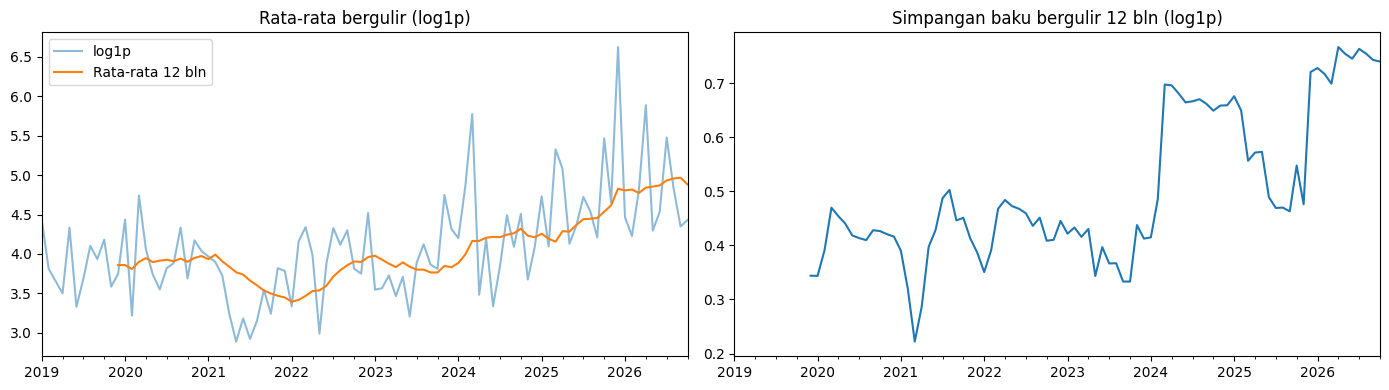

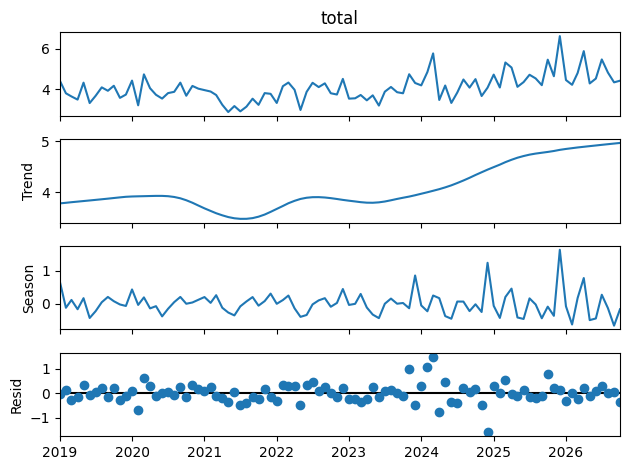

Kekuatan tren = 0.57 | kekuatan musiman = 0.39 (0 = tidak ada, 1 = sangat kuat)

Ljung-Box (log1p, d=1):
    lb_stat  lb_pvalue
3    22.842      0.000
6    23.278      0.001
12   27.559      0.006


In [16]:
# Rolling mean/std: apakah rata-rata & variansi stabil?
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
log_nilai.plot(ax=ax[0], alpha=.5, label="log1p")
log_nilai.rolling(12).mean().plot(ax=ax[0], label="Rata-rata 12 bln")
ax[0].legend(); ax[0].set_title("Rata-rata bergulir (log1p)")
log_nilai.rolling(12).std().plot(ax=ax[1], title="Simpangan baku bergulir 12 bln (log1p)")
plt.tight_layout(); plt.show()

# STL (butuh >= 24 bulan)
if len(log_nilai) >= 24:
    stl = STL(log_nilai, period=12, robust=True).fit()
    stl.plot(); plt.show()
    var_r = stl.resid.var()
    kekuatan_musim = max(0, 1 - var_r / (stl.seasonal + stl.resid).var())
    kekuatan_tren = max(0, 1 - var_r / (stl.trend + stl.resid).var())
    print(f"Kekuatan tren = {kekuatan_tren:.2f} | kekuatan musiman = {kekuatan_musim:.2f} "
          f"(0 = tidak ada, 1 = sangat kuat)")
else:
    print("Data < 24 bulan, STL dilewati")

# Ljung-Box: p < 0.05 = ada autokorelasi (ada pola yang bisa dimodelkan)
lb = acorr_ljungbox(log_nilai.diff().dropna(), lags=[3, 6, 12], return_df=True)
print("\nLjung-Box (log1p, d=1):")
print(lb.round(3).to_string())

#**UJI KUARTALAN**

Jumlah kuartal: 31 | CV kuartalan: 0.85 (bulanan: 1.17)
                    ADF p  KPSS p
Log kuartalan       0.997   0.023
Log kuartalan, d=1  0.012   0.100


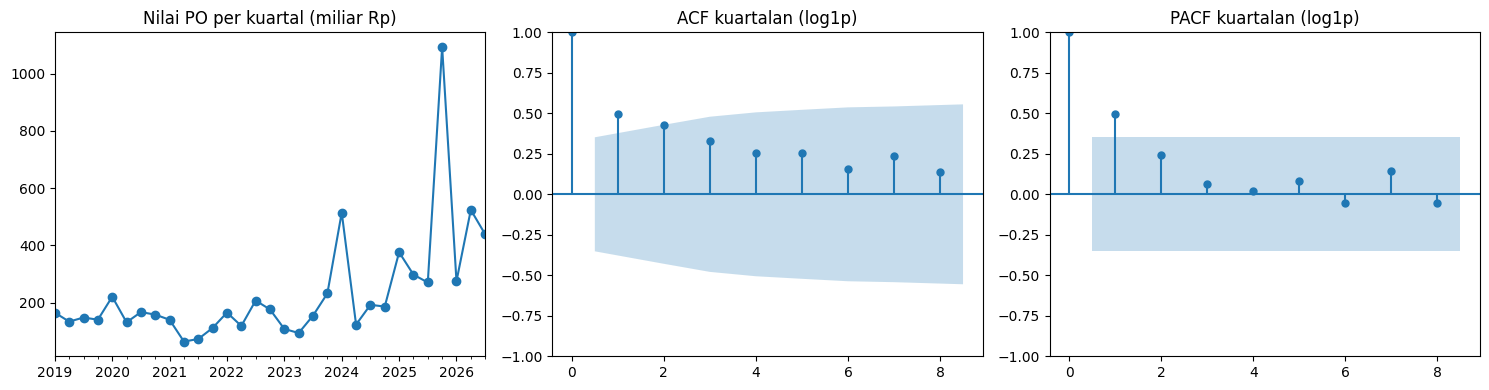

In [15]:
kuartal = nilai_miliar.resample("QS").agg(["sum", "count"])
kuartal = kuartal[kuartal["count"] == 3]["sum"]          # buang kuartal tidak lengkap
log_q = np.log1p(kuartal)

hasil = pd.DataFrame({
    "Log kuartalan": uji_stasioner(log_q),
    "Log kuartalan, d=1": uji_stasioner(log_q.diff()),
}).T.round(3)
print(f"Jumlah kuartal: {len(kuartal)} | CV kuartalan: {kuartal.std() / kuartal.mean():.2f} "
      f"(bulanan: {nilai_miliar.std() / nilai_miliar.mean():.2f})")
print(hasil.to_string())

nlag = max(1, min(8, len(log_q) // 2 - 1))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
kuartal.plot(ax=ax[0], marker="o", title="Nilai PO per kuartal (miliar Rp)")
plot_acf(log_q, lags=nlag, ax=ax[1], title="ACF kuartalan (log1p)")
plot_pacf(log_q, lags=nlag, ax=ax[2], title="PACF kuartalan (log1p)")
plt.tight_layout(); plt.show()